# 04 · E4: MNIST Lojistik Regresyon (Konveks)

**Amaç:** Reddi, Kale & Kumar (ICLR 2018) Bölüm 5.2 / Şekil 2'deki konveks MNIST çok sınıflı lojistik regresyon deneyini (`784 → 10`) ortak `PaperAdam` ve `PaperAMSGrad` implementasyonlarımızla yeniden üretmek.

**Adımlar (Proje Planı H1.3, H2.1, H3.1):**
1. **Baseline (`H1.3`):** `torch.optim.Adam` ile 5000 iterasyon, batch 128 kontrolü (train loss ≈ 0.25–0.30 aralığında mı?).
2. **Grid Search (`H2.1`):** `seed = 0` üzerinde `PaperAdam` vs `PaperAMSGrad`, $\alpha_t = \alpha / \sqrt{t}$, $\alpha \in \{0.003, 0.01, 0.03, 0.1, 0.3, 1\}$, $\beta_2 \in \{0.99, 0.999\}$, $\beta_1 = 0.9$, 5000 iterasyon. Seçim kriteri: **son 500 iterasyonun ortalama train loss'u**.
3. **Final 5 Seed (`H3.1`):** Her iki optimizer için seçilen en iyi $(\alpha, \beta_2)$ ile `seed = 0, 1, 2, 3, 4` koşuları, Bölüm 2.2 formatında CSV kaydı (`results/e4_mnist_logreg/`) ve ortalama ± std figürü (`figures/e4.png` + `.pdf`).

**Kaggle ayarları:** Accelerator: **GPU T4**. MNIST Kaggle Dataset ekli ise internetsiz çalışır; yoksa `torchvision` fallback kullanılır.

## Makaleden sapmalar
- **Grid search $\alpha$ kümesi:** Makale grid search'te denenen $\alpha$ değerlerini belirtmiyor. Her iki optimizer'a eşit bütçeyle $\alpha \in \{0.003, 0.01, 0.03, 0.1, 0.3, 1.0\}$ ve $\beta_2 \in \{0.99, 0.999\}$ tarandı; seçim kriteri önceden **son 500 iterasyonun ortalama minibatch train loss'u** olarak belirlendi.
- **$\varepsilon$ ve bias correction:** Makale gerçek veri deneylerinde $\varepsilon$ ve bias correction tercihlerini açıklamıyor. Bu deneyde standart pratik olan `eps = 1e-8` ve `bias_correction = True` kullanıldı (her iki optimizer için aynı).
- **Veri ön işleme:** MNIST görüntüleri `[0, 1]`'e ölçeklenip standart normalize edildi (`mean = 0.1307`, `std = 0.3081`).
- **Framework ve seed:** TensorFlow yerine PyTorch kullanıldı. Makalede tek eğri raporlanıyor; biz 5 seed (`0, 1, 2, 3, 4`) ile koşup ortalama ± std raporluyoruz. Aynı seed'de Adam ve AMSGrad birebir aynı başlangıç ağırlıklarını ve aynı minibatch dizisini görür.
- **Değerlendirme metriği:** Eğitim eğrilerini gürültüsüz izlemek için her 50 iterasyonda tüm eğitim (60k) ve test (10k) kümeleri üzerinde Cross-Entropy loss ve test accuracy hesaplandı.

In [1]:
# --- Kurulum: repo ve cihaz ---
import os, sys, subprocess
REPO = "https://github.com/ybilgici/DeepLearning_Proje.git"
if os.path.exists("/kaggle"):
    ROOT = "/kaggle/working/DeepLearning_Proje"
    if not os.path.exists(ROOT):
        subprocess.run(["git", "clone", "-q", REPO, ROOT], check=True)
    else:
        subprocess.run(["git", "-C", ROOT, "pull", "-q"], check=True)
else:
    ROOT = os.path.abspath("..")
if ROOT not in sys.path:
    sys.path.insert(0, ROOT)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from common.data import load_mnist
from common.mnist_exp import (
    STYLE,
    build_mnist_logreg,
    plot_train_test_curves,
    run_final_seeds,
    run_grid_search,
    run_single_mnist,
    summarize_final_runs,
)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
RESULTS_DIR = os.path.join(ROOT, "results", "e4_mnist_logreg")
FIGURES_DIR = os.path.join(ROOT, "figures")
os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(FIGURES_DIR, exist_ok=True)

print("Device:", DEVICE, "| torch:", torch.__version__)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
print("Commit:", subprocess.run(["git", "-C", ROOT, "rev-parse", "--short", "HEAD"],
                                capture_output=True, text=True).stdout.strip())

Device: cuda | torch: 2.11.0+cu128
GPU: NVIDIA GeForce RTX 5070
Commit: d0b821c


In [2]:
# --- MNIST verisini GPU tensörleri olarak yükle (DataLoader yok) ---
X_train, y_train, X_test, y_test = load_mnist(device=DEVICE, flatten=True, normalize="standard")
print(f"X_train: {tuple(X_train.shape)} {X_train.dtype} on {X_train.device} | mean={X_train.mean():.3f}, std={X_train.std():.3f}")
print(f"X_test : {tuple(X_test.shape)} {X_test.dtype} on {X_test.device} | y range=[{y_test.min().item()}, {y_test.max().item()}]")

X_train: (60000, 784) torch.float32 on cuda:0 | mean=-0.000, std=1.000


X_test : (10000, 784) torch.float32 on cuda:0 | y range=[0, 9]


## 1. Baseline Kontrolü (H1.3): `torch.optim.Adam`
5000 iterasyon, batch 128, sabit `lr = 1e-3`. Beklenti: eğitim loss'u makaledeki aralıkta (~0.25–0.30).

Baseline torch.optim.Adam (5000 iter): last500_mb_loss=0.2508 | full_train_loss=0.2517 | test_loss=0.2754 | test_acc=92.27% (15.6s)


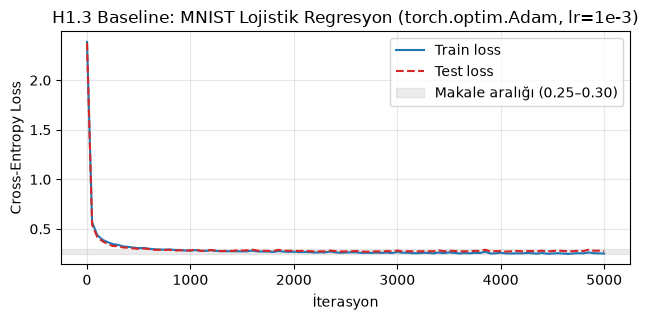

In [3]:
baseline = run_single_mnist(
    "e4_baseline",
    build_mnist_logreg,
    X_train, y_train, X_test, y_test,
    optimizer_name="torch_adam",
    lr=1e-3,
    beta1=0.9,
    beta2=0.999,
    eps=1e-8,
    lr_schedule="const",
    steps=5000,
    batch_size=128,
    seed=0,
    eval_every=50,
)
print(
    f"Baseline torch.optim.Adam (5000 iter): "
    f"last500_mb_loss={baseline['last500_train_loss']:.4f} | "
    f"full_train_loss={baseline['final_train_loss']:.4f} | "
    f"test_loss={baseline['final_test_loss']:.4f} | "
    f"test_acc={baseline['final_test_acc']*100:.2f}% ({baseline['seconds']:.1f}s)"
)

bh = baseline["history"]
fig, ax = plt.subplots(figsize=(6.5, 3.3))
ax.plot(bh["step"], bh["train_loss"], label="Train loss", color="#1f77b4")
ax.plot(bh["step"], bh["test_loss"], "--", label="Test loss", color="#d62728")
ax.axhspan(0.25, 0.30, color="gray", alpha=0.15, label="Makale aralığı (0.25–0.30)")
ax.set_xlabel("İterasyon"); ax.set_ylabel("Cross-Entropy Loss")
ax.set_title("H1.3 Baseline: MNIST Lojistik Regresyon (torch.optim.Adam, lr=1e-3)")
ax.grid(True, alpha=0.3); ax.legend(); plt.tight_layout(); plt.show()
assert 0.20 <= baseline["final_train_loss"] <= 0.35, "Baseline loss beklenen aralıkta değil!"

## 2. Grid Search (H2.1 — Seed 0)
`PaperAdam` vs `PaperAMSGrad`, $\alpha_t = \alpha / \sqrt{t}$, $\alpha \in \{0.003, 0.01, 0.03, 0.1, 0.3, 1\}$, $\beta_2 \in \{0.99, 0.999\}$, $\beta_1 = 0.9$, 5000 iterasyon.
Seçim kriteri: **son 500 iterasyonun ortalama train loss'u**.

In [4]:
E4_LRS = [0.003, 0.01, 0.03, 0.1, 0.3, 1.0]
E4_BETA2S = [0.99, 0.999]
E4_STEPS = 5000
E4_BATCH = 128
E4_EPS = 1e-8
E4_BIAS_CORRECTION = True

grid_df, best_cfgs = run_grid_search(
    "e4",
    build_mnist_logreg,
    X_train, y_train, X_test, y_test,
    lrs=E4_LRS,
    beta2s=E4_BETA2S,
    beta1=0.9,
    eps=E4_EPS,
    bias_correction=E4_BIAS_CORRECTION,
    lr_schedule="sqrt",
    steps=E4_STEPS,
    batch_size=E4_BATCH,
    seed=0,
    eval_every=250,
    selection_window=500,
)
grid_path = os.path.join(RESULTS_DIR, "grid_summary.csv")
grid_df.to_csv(grid_path, index=False)
print("\nGrid tablosu kaydedildi:", grid_path)
print("\nSeçilen en iyi konfigürasyonlar (son 500 iterasyon ortalama train loss'una göre):")
for opt_name, c in best_cfgs.items():
    print(f"  {opt_name:7s}: lr={c['lr']:g}, beta2={c['beta2']:g} -> last500={c['last500_train_loss']:.4f}, full_tr={c['final_train_loss']:.4f}, te_loss={c['final_test_loss']:.4f}, te_acc={c['final_test_acc']*100:.2f}%")

grid_df.sort_values(["optimizer", "last500_train_loss"]).reset_index(drop=True)

[adam   ] lr=0.003   beta2=0.99  | last500_tr=0.2890 full_tr=0.2913 te_loss=0.2855 te_acc=91.87% (6.1s)


[adam   ] lr=0.01    beta2=0.99  | last500_tr=0.2581 full_tr=0.2614 te_loss=0.2695 te_acc=92.34% (6.6s)


[adam   ] lr=0.03    beta2=0.99  | last500_tr=0.2452 full_tr=0.2475 te_loss=0.2710 te_acc=92.46% (7.8s)


[adam   ] lr=0.1     beta2=0.99  | last500_tr=0.2482 full_tr=0.2485 te_loss=0.2921 te_acc=92.27% (7.4s)


[adam   ] lr=0.3     beta2=0.99  | last500_tr=0.2998 full_tr=0.3148 te_loss=0.4004 te_acc=91.02% (7.2s)


[adam   ] lr=1       beta2=0.99  | last500_tr=0.6820 full_tr=0.6493 te_loss=0.9226 te_acc=90.08% (8.3s)


... (15 outputs left out)

[amsgrad] lr=0.1     beta2=0.999 | last500_tr=0.2477 full_tr=0.2477 te_loss=0.2898 te_acc=92.21% (8.2s)


[amsgrad] lr=0.3     beta2=0.999 | last500_tr=0.2946 full_tr=0.3102 te_loss=0.3951 te_acc=91.04% (7.8s)


[amsgrad] lr=1       beta2=0.999 | last500_tr=0.6707 full_tr=0.6396 te_loss=0.9140 te_acc=90.36% (7.8s)

Grid tablosu kaydedildi: C:\Users\test\.gemini\antigravity\scratch\DeepLearning_Proje\results\e4_mnist_logreg\grid_summary.csv

Seçilen en iyi konfigürasyonlar (son 500 iterasyon ortalama train loss'una göre):
  adam   : lr=0.03, beta2=0.99 -> last500=0.2452, full_tr=0.2475, te_loss=0.2710, te_acc=92.46%
  amsgrad: lr=0.1, beta2=0.99 -> last500=0.2455, full_tr=0.2479, te_loss=0.2899, te_acc=92.26%


,exp,optimizer,seed,lr,beta1,beta2,last500_train_loss,final_train_loss,final_test_loss,final_test_acc,seconds
0,e4,adam,0,0.030,0.9,0.990,0.245199,0.247476,0.270956,0.9246,7.78
1,e4,adam,0,0.030,0.9,0.999,0.246124,0.248409,0.270887,0.9244,7.26
2,e4,adam,0,0.100,0.9,0.990,0.248152,0.248511,0.292133,0.9227,7.40
3,e4,adam,0,0.100,0.9,0.999,0.248481,0.248092,0.290341,0.9217,8.13
4,e4,adam,0,0.010,0.9,0.990,0.258112,0.261419,0.269529,0.9234,6.60
5,e4,adam,0,0.010,0.9,0.999,0.259240,0.262470,0.269943,0.9232,7.33
6,e4,adam,0,0.003,0.9,0.990,0.288996,0.291257,0.285498,0.9187,6.12
7,e4,adam,0,0.003,0.9,0.999,0.292414,0.294405,0.287816,0.9182,7.93
8,e4,adam,0,0.300,0.9,0.999,0.298473,0.312454,0.396863,0.9103,8.25
9,e4,adam,0,0.300,0.9,0.990,0.299829,0.314825,0.400368,0.9102,7.20


## 3. Final Koşuları (H3.1 — 5 Seed: `0, 1, 2, 3, 4`)
Her optimizer için grid search ile seçilen en iyi $(\alpha, \beta_2)$ çiftiyle 5 seed koşulur ve Bölüm 2.2 formatındaki CSV'ler `results/e4_mnist_logreg/` altına kaydedilir.

In [5]:
final_df = run_final_seeds(
    "e4",
    build_mnist_logreg,
    X_train, y_train, X_test, y_test,
    best_cfgs=best_cfgs,
    results_dir=RESULTS_DIR,
    seeds=(0, 1, 2, 3, 4),
    eps=E4_EPS,
    bias_correction=E4_BIAS_CORRECTION,
    lr_schedule="sqrt",
    steps=E4_STEPS,
    batch_size=E4_BATCH,
    eval_every=50,
)

summary_df = summarize_final_runs(final_df)
for _, r in summary_df.iterrows():
    print(
        f"{r['optimizer']:7s} (lr={r['lr']:g}, b2={r['beta2']:g}, n={int(r['n_seeds'])}): "
        f"train_loss = {r['train_loss_mean']:.4f} ± {r['train_loss_std']:.4f} | "
        f"test_loss = {r['test_loss_mean']:.4f} ± {r['test_loss_std']:.4f} | "
        f"test_acc = {r['test_acc_mean']*100:.2f}% ± {r['test_acc_std']*100:.2f}%"
    )
summary_df

[FINAL adam   ] seed=0 lr=0.03    b2=0.99  | tr_loss=0.2475 te_loss=0.2710 te_acc=92.46% -> adam_seed0.csv


[FINAL adam   ] seed=1 lr=0.03    b2=0.99  | tr_loss=0.2471 te_loss=0.2677 te_acc=92.43% -> adam_seed1.csv


[FINAL adam   ] seed=2 lr=0.03    b2=0.99  | tr_loss=0.2482 te_loss=0.2692 te_acc=92.55% -> adam_seed2.csv


[FINAL adam   ] seed=3 lr=0.03    b2=0.99  | tr_loss=0.2482 te_loss=0.2700 te_acc=92.45% -> adam_seed3.csv


[FINAL adam   ] seed=4 lr=0.03    b2=0.99  | tr_loss=0.2473 te_loss=0.2694 te_acc=92.37% -> adam_seed4.csv


[FINAL amsgrad] seed=0 lr=0.1     b2=0.99  | tr_loss=0.2479 te_loss=0.2899 te_acc=92.26% -> amsgrad_seed0.csv


[FINAL amsgrad] seed=1 lr=0.1     b2=0.99  | tr_loss=0.2459 te_loss=0.2810 te_acc=92.33% -> amsgrad_seed1.csv


[FINAL amsgrad] seed=2 lr=0.1     b2=0.99  | tr_loss=0.2475 te_loss=0.2842 te_acc=92.45% -> amsgrad_seed2.csv


[FINAL amsgrad] seed=3 lr=0.1     b2=0.99  | tr_loss=0.2492 te_loss=0.2855 te_acc=92.15% -> amsgrad_seed3.csv


[FINAL amsgrad] seed=4 lr=0.1     b2=0.99  | tr_loss=0.2461 te_loss=0.2825 te_acc=92.20% -> amsgrad_seed4.csv
adam    (lr=0.03, b2=0.99, n=5): train_loss = 0.2477 ± 0.0005 | test_loss = 0.2694 ± 0.0012 | test_acc = 92.45% ± 0.06%
amsgrad (lr=0.1, b2=0.99, n=5): train_loss = 0.2473 ± 0.0014 | test_loss = 0.2846 ± 0.0034 | test_acc = 92.28% ± 0.12%


,optimizer,lr,beta1,beta2,n_seeds,train_loss_mean,train_loss_std,test_loss_mean,test_loss_std,test_acc_mean,test_acc_std
0,adam,0.03,0.9,0.99,5,0.247676,0.000503,0.269427,0.001212,0.92452,0.000650
1,amsgrad,0.10,0.9,0.99,5,0.247321,0.001373,0.284644,0.003420,0.92278,0.001173


## 4. Final Figürü (`figures/e4.png` ve `figures/e4.pdf`)
Adam kırmızı kesikli, AMSGrad mavi düz çizgi; 5 seed üzerinden ortalama ± std bandı.

Kaydedildi: C:\Users\test\.gemini\antigravity\scratch\DeepLearning_Proje\figures\e4.png / .pdf


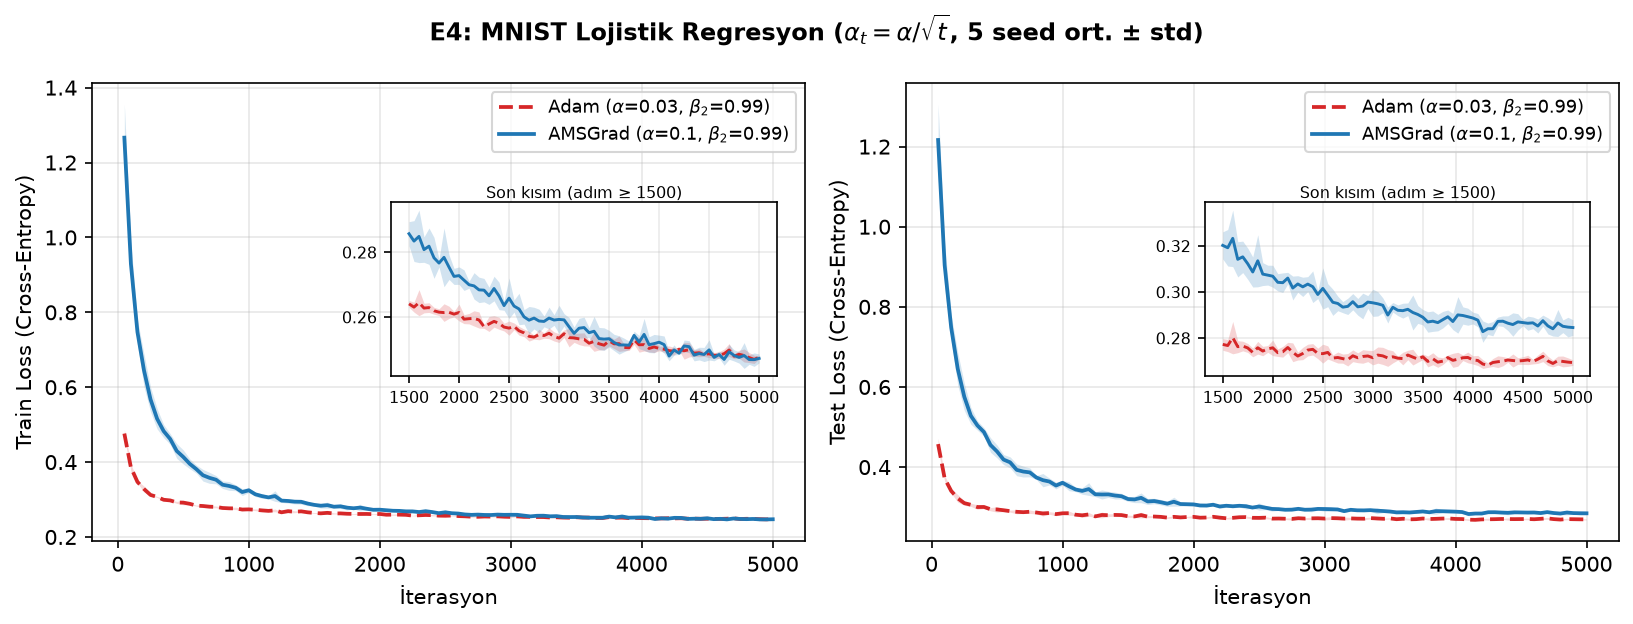

In [6]:
fig = plot_train_test_curves(
    final_df,
    title="E4: MNIST Lojistik Regresyon ($\\alpha_t = \\alpha/\\sqrt{t}$, 5 seed ort. ± std)",
    save_name="e4",
    figures_dir=FIGURES_DIR,
    best_cfgs=best_cfgs,
    min_step=50,
    zoom_from=1500,
)
plt.show()
assert os.path.isfile(os.path.join(FIGURES_DIR, "e4.png"))
assert os.path.isfile(os.path.join(FIGURES_DIR, "e4.pdf"))